In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
import matplotlib.pyplot as plt

In [13]:
train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')

In [14]:
X_train = train_data.iloc[:, :-1].values
y_train = train_data.iloc[:, -1].values
X_test = test_data.values

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [15]:
model = Sequential([
    Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

d:\Anaconda\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

In [17]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 30ms/step - accuracy: 0.2755 - loss: 1.9731 - val_accuracy: 0.3494 - val_loss: 1.8142
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.3397 - loss: 1.8224 - val_accuracy: 0.3668 - val_loss: 1.7386
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.3566 - loss: 1.7721 - val_accuracy: 0.3664 - val_loss: 1.7566
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.3732 - loss: 1.7345 - val_accuracy: 0.3724 - val_loss: 1.7183
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.3818 - loss: 1.7079 - val_accuracy: 0.4110 - val_loss: 1.6438


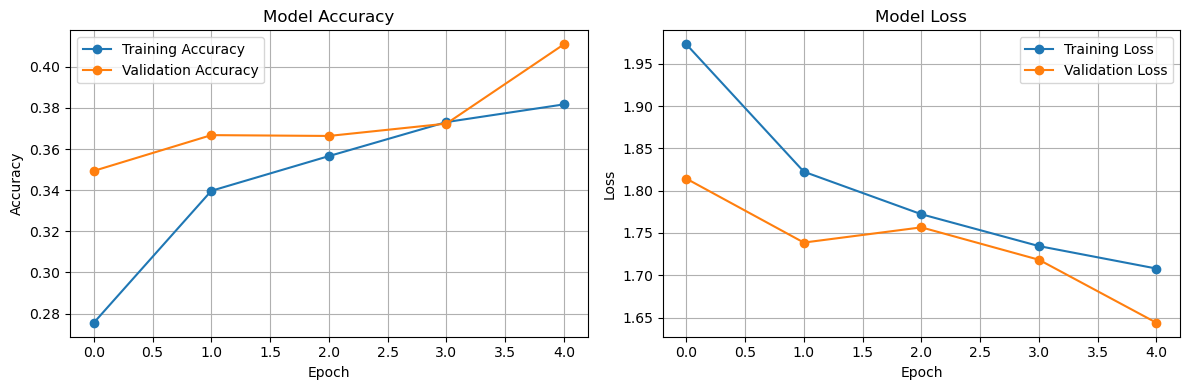

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [19]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 
               'dog', 'frog', 'horse', 'ship', 'truck']

In [20]:
sample_idx = 0
img_flat = X_test[sample_idx]

prediction_probs = model.predict(img_flat.reshape(1, -1))
predicted_label = np.argmax(prediction_probs)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 782ms/step


In [21]:
print(f"Predicted Class: {class_names[predicted_label]}")

Predicted Class: cat


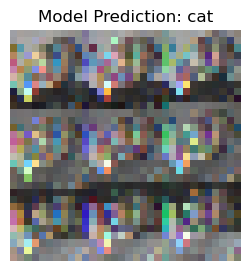

In [22]:
plt.figure(figsize=(3, 3))
try:
    img_reshaped = img_flat.reshape(32, 32, 3) 
    plt.imshow(img_reshaped)
    plt.title(f"Model Prediction: {class_names[predicted_label]}")
    plt.axis('off')
    plt.show()
except Exception as e:
    print(f"Could not reshape image for display: {e}")